# 02. Análise temporal e estacionariedade

A análise começa com as séries nacionais em nível, examina sua evolução temporal e sazonalidade, compara transformações e apresenta testes ADF e KPSS, decomposições clássica e STL e gráficos ACF/PACF. As duas janelas são a **pré-pandemia (até janeiro de 2020)** e a **completa (até dezembro de 2024)**.

A série nacional de inadimplência é calculada a partir dos saldos agregados do SCR, e a contagem de desastres é agregada a partir dos registros do Atlas. O arquivo mensal nacional publicado é suficiente para reproduzir os gráficos e os testes desta etapa. Os diagnósticos estaduais, realizados na preparação dos modelos posteriores, são apresentados separadamente.

**Distinção importante:** a primeira análise nacional adotou `ΔI` (pontos percentuais) e `Δlog(1 + D)`; os modelos estaduais de Granger e DLM adotam `Δlog(I)` e `Δlog(1 + D)`. A mudança de transformação altera a interpretação dos coeficientes, mas não o indicador de inadimplência definido na origem.

## 1. Bibliotecas, período e dados

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from scipy.stats import kruskal

def raiz_projeto():
    for pasta in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (pasta / "outputs" / "tables").exists() and (pasta / "src").exists():
            return pasta
    raise FileNotFoundError("Abra o notebook a partir da pasta do projeto.")

ROOT = raiz_projeto()
TAB = ROOT / "outputs" / "tables"
bruto = pd.read_csv(TAB / "segunda_etapa/series_nacionais_agregadas.csv", encoding="utf-8-sig")
bruto["data"] = pd.to_datetime(bruto["data"])
bruto = bruto.set_index("data").sort_index().asfreq("MS")
series = bruto[["I", "Total nacional"]].rename(columns={
    "I": "Inadimplência (%)", "Total nacional": "Registros de desastres"})
assert len(series) == 144 and not series.isna().any().any()
assert series["Inadimplência (%)"].gt(0).all()
assert series["Registros de desastres"].ge(0).all()
RECORTES = {"pré-pandemia": series.loc[:"2020-01-01"], "completo": series}
plt.rcParams.update({"figure.figsize": (12, 4.5), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
print("Meses:", len(series), "| início:", series.index.min().date(), "| fim:", series.index.max().date())
display(series.describe().round(3))

Meses: 144 | início: 2013-01-01 | fim: 2024-12-01


,Inadimplência (%),Registros de desastres
count,144.000,144.000
mean,3.842,280.132
std,0.458,188.756
min,2.848,48.000
25%,3.596,157.500
50%,3.840,235.000
75%,4.136,357.250
max,5.032,1408.000


## 2. Gráficos das séries originais

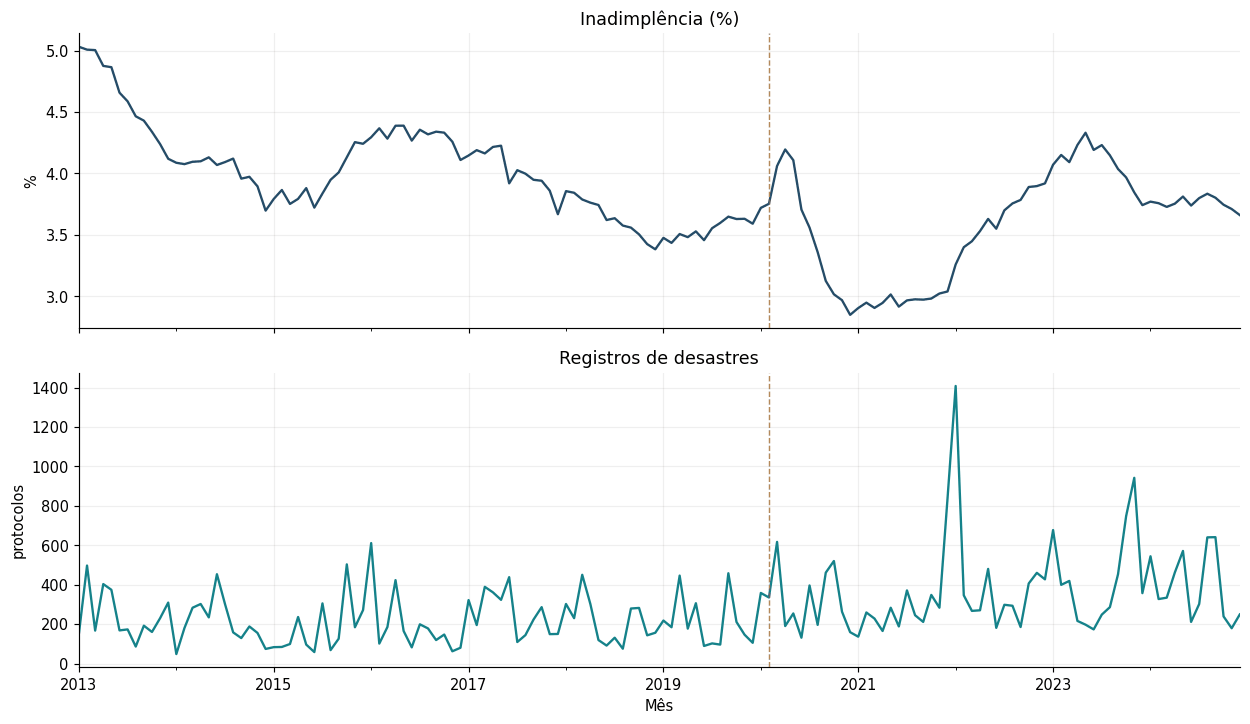

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, col, color in zip(axes, series.columns, ["#254c68", "#15828a"]):
    series[col].plot(ax=ax, color=color, lw=1.6)
    ax.axvline(pd.Timestamp("2020-02-01"), color="#a36d32", ls="--", lw=1, alpha=.8)
    ax.set(title=col, xlabel="", ylabel="%" if col.startswith("Inadimplência") else "protocolos")
axes[-1].set_xlabel("Mês")
plt.tight_layout()
plt.show()

## 3. Descritiva temporal e sazonalidade

Recorte: pré-pandemia | 85 meses
Recorte: completo | 144 meses
Inadimplência (%) - Kruskal-Wallis: p = 0.97066
Registros de desastres - Kruskal-Wallis: p = 0.16074


,count,mean,std,min,25%,50%,75%,max
Inadimplência (%),85.0,4.013,0.387,3.382,3.72,3.998,4.255,5.032
Registros de desastres,85.0,216.776,125.371,48.000,119.00,180.000,302.000,611.000


,count,mean,std,min,25%,50%,75%,max
Inadimplência (%),144.0,3.842,0.458,2.848,3.596,3.84,4.136,5.032
Registros de desastres,144.0,280.132,188.756,48.000,157.500,235.00,357.250,1408.000


Inadimplência (%)              Registros de desastres               
                  mean median   std                   mean median     std
data                                                                     
1                 3.87   3.82  0.54                 404.92  312.0  377.06
2                 3.90   3.85  0.53                 261.42  244.5  123.04
3                 3.90   3.92  0.52                 323.67  308.5  147.31
4                 3.94   3.95  0.50                 292.25  286.0  101.13
5                 3.97   3.99  0.48                 283.50  268.5  140.97
6                 3.82   3.73  0.45                 188.58  170.5  129.52
7                 3.86   3.82  0.43                 244.58  273.0  100.33
8                 3.84   3.89  0.42                 205.42  168.0  157.70
9                 3.80   3.88  0.43                 289.75  217.0  170.77
10                3.79   3.92  0.44                 336.50  284.0  179.79
11                3.75   3.85  0.44                 266.33  181.5  235.03
12                3.67   3.68  0.42                 264.67  204.0  213.00

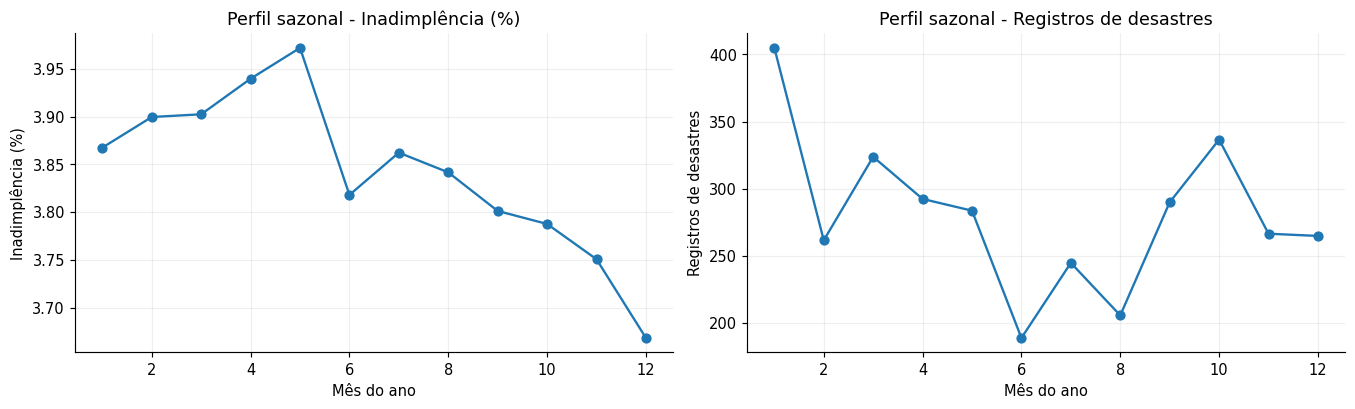

In [3]:
for nome, parte in RECORTES.items():
    print("Recorte:", nome, "|", len(parte), "meses")
    display(parte.describe().T.round(3))

perfil = series.groupby(series.index.month).agg(["mean", "median", "std"])
display(perfil.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, series.columns):
    media = series.groupby(series.index.month)[col].mean()
    ax.plot(media.index, media.values, marker="o", lw=1.6)
    ax.set(title="Perfil sazonal - " + col, xlabel="Mês do ano", ylabel=col)
    grupos = [g.values for _,g in series[col].groupby(series.index.month)]
    print(col, "- Kruskal-Wallis: p =", round(kruskal(*grupos).pvalue, 5))
plt.tight_layout()
plt.show()

A sazonalidade visual é importante para a identificação dos modelos e para justificar controles mensais ou componentes sazonais anuais. O teste de Kruskal-Wallis compara as distribuições mensais, mas não substitui os diagnósticos de autocorrelação.

## 4. Decomposição clássica e STL das séries originais

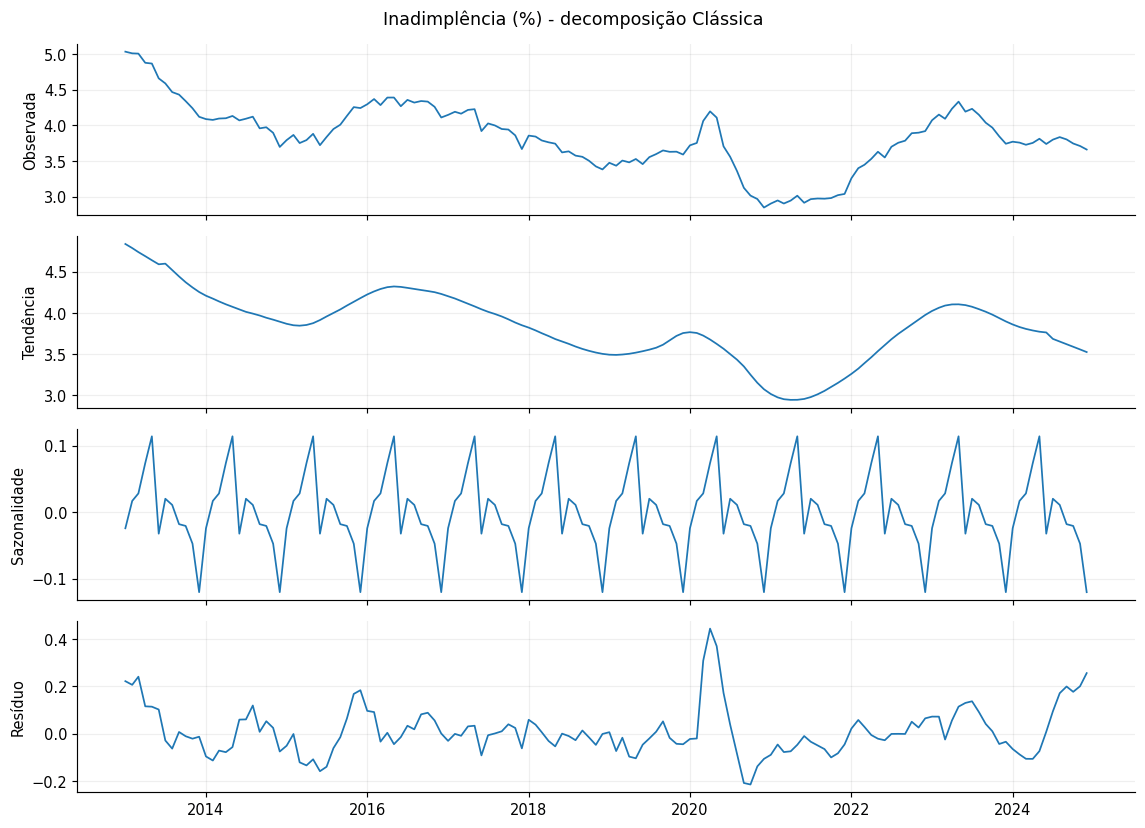

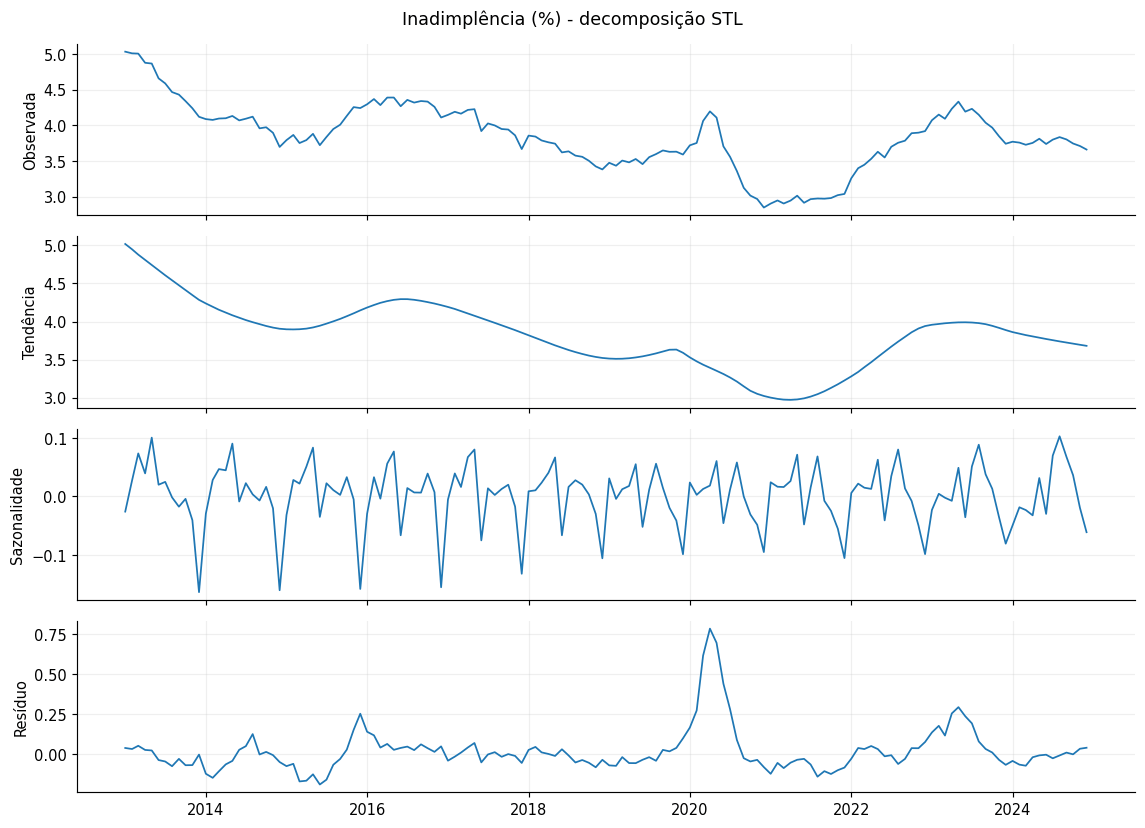

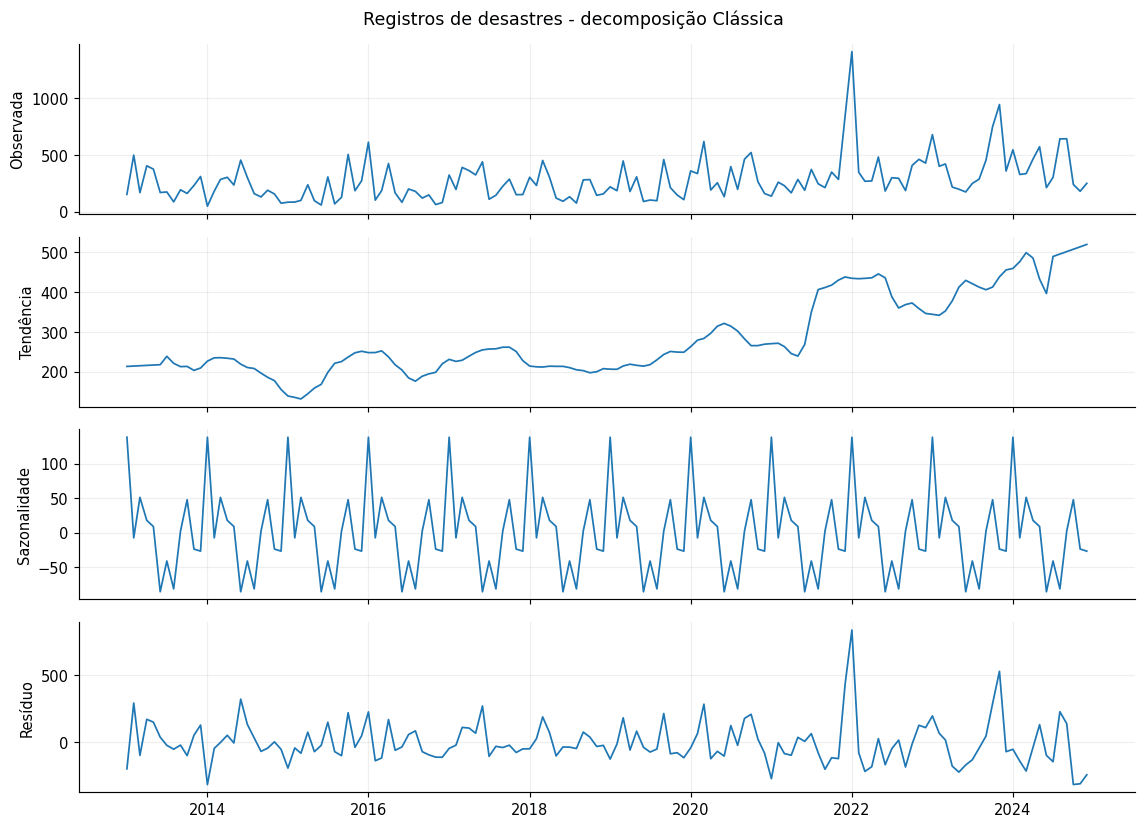

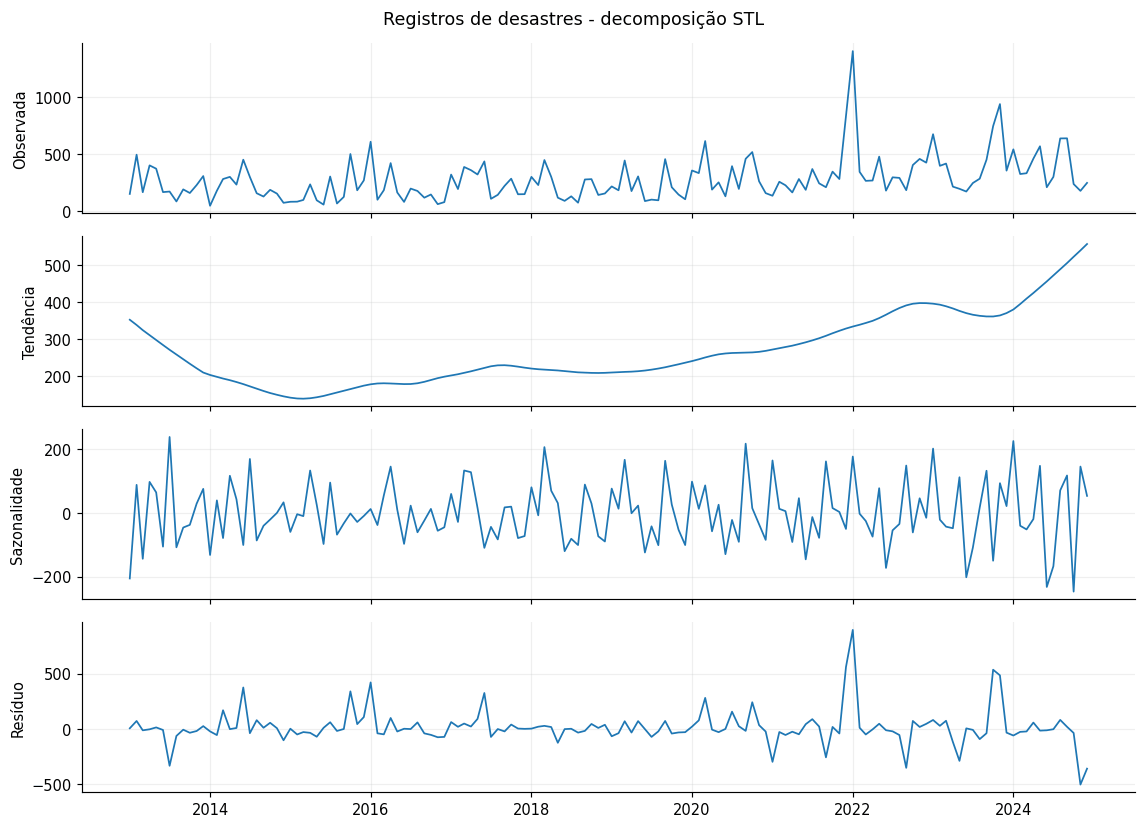

02_estacionariedade.ipynb::cell_9:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
02_estacionariedade.ipynb::cell_9:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.


In [4]:
def mostrar_decomposicoes(s, titulo):
    s = s.astype(float).dropna().asfreq("MS")
    clas = seasonal_decompose(s, model="additive", period=12, extrapolate_trend="freq")
    stl = STL(s, period=12, robust=True).fit()
    for metodo, componentes in [("Clássica", clas), ("STL", stl)]:
        fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
        for eixo, campo, titulo_eixo in zip(ax, [s, componentes.trend, componentes.seasonal, componentes.resid],
                                             ["Observada", "Tendência", "Sazonalidade", "Resíduo"]):
            eixo.plot(campo.index, campo.values, lw=1.2)
            eixo.set_ylabel(titulo_eixo)
        fig.suptitle(f"{titulo} - decomposição {metodo}")
        fig.tight_layout()
        plt.show()

for nome in series.columns:
    mostrar_decomposicoes(series[nome], nome)

A decomposição clássica representa a série como tendência, sazonalidade e resíduo, com sazonalidade fixa. A STL permite uma sazonalidade suavemente variável e usa ajuste robusto para reduzir a influência de observações atípicas. As decomposições ajudam no diagnóstico, mas não são testes formais de estacionariedade.

## 5. Transformações candidatas e suas interpretações

In [5]:
def transformacoes(s, contagem):
    s = pd.Series(s, copy=True).astype(float)
    log_s = np.log1p(s) if contagem else np.log(s)
    return {
        "nível": s,
        "log(1+D)" if contagem else "log(I)": log_s,
        "Δ nível": s.diff(),
        "Δlog(1+D)" if contagem else "Δlog(I)": log_s.diff(),
        "Δ12 nível": s.diff(12),
        "ΔΔ12 nível": s.diff().diff(12),
        "ΔΔ12 log(1+D)" if contagem else "ΔΔ12 log(I)": log_s.diff().diff(12),
    }

transformadas = {
    "Inadimplência (%)": transformacoes(series["Inadimplência (%)"], False),
    "Registros de desastres": transformacoes(series["Registros de desastres"], True),
}
significado = pd.DataFrame([
    {"Transformação": "nível", "Interpretação": "valor original da série"},
    {"Transformação": "log(I)", "Interpretação": "logaritmo natural da taxa (positiva)"},
    {"Transformação": "log(1+D)", "Interpretação": "logaritmo da contagem mais um (admite zeros)"},
    {"Transformação": "Δ nível", "Interpretação": "diferença entre meses; para I, em pontos percentuais"},
    {"Transformação": "Δlog", "Interpretação": "mudança logarítmica mensal; escala proporcional aproximada"},
    {"Transformação": "Δ12 nível", "Interpretação": "diferença entre o mesmo mês de anos consecutivos"},
    {"Transformação": "ΔΔ12", "Interpretação": "primeira diferença seguida da diferença sazonal anual"},
])
display(significado)

,Transformação,Interpretação
0,nível,valor original da série
1,log(I),logaritmo natural da taxa (positiva)
2,log(1+D),logaritmo da contagem mais um (admite zeros)
3,Δ nível,"diferença entre meses; para I, em pontos percentuais"
4,Δlog,mudança logarítmica mensal; escala proporcional aproximada
5,Δ12 nível,diferença entre o mesmo mês de anos consecutivos
6,ΔΔ12,primeira diferença seguida da diferença sazonal anual


## 6. Gráficos das transformações

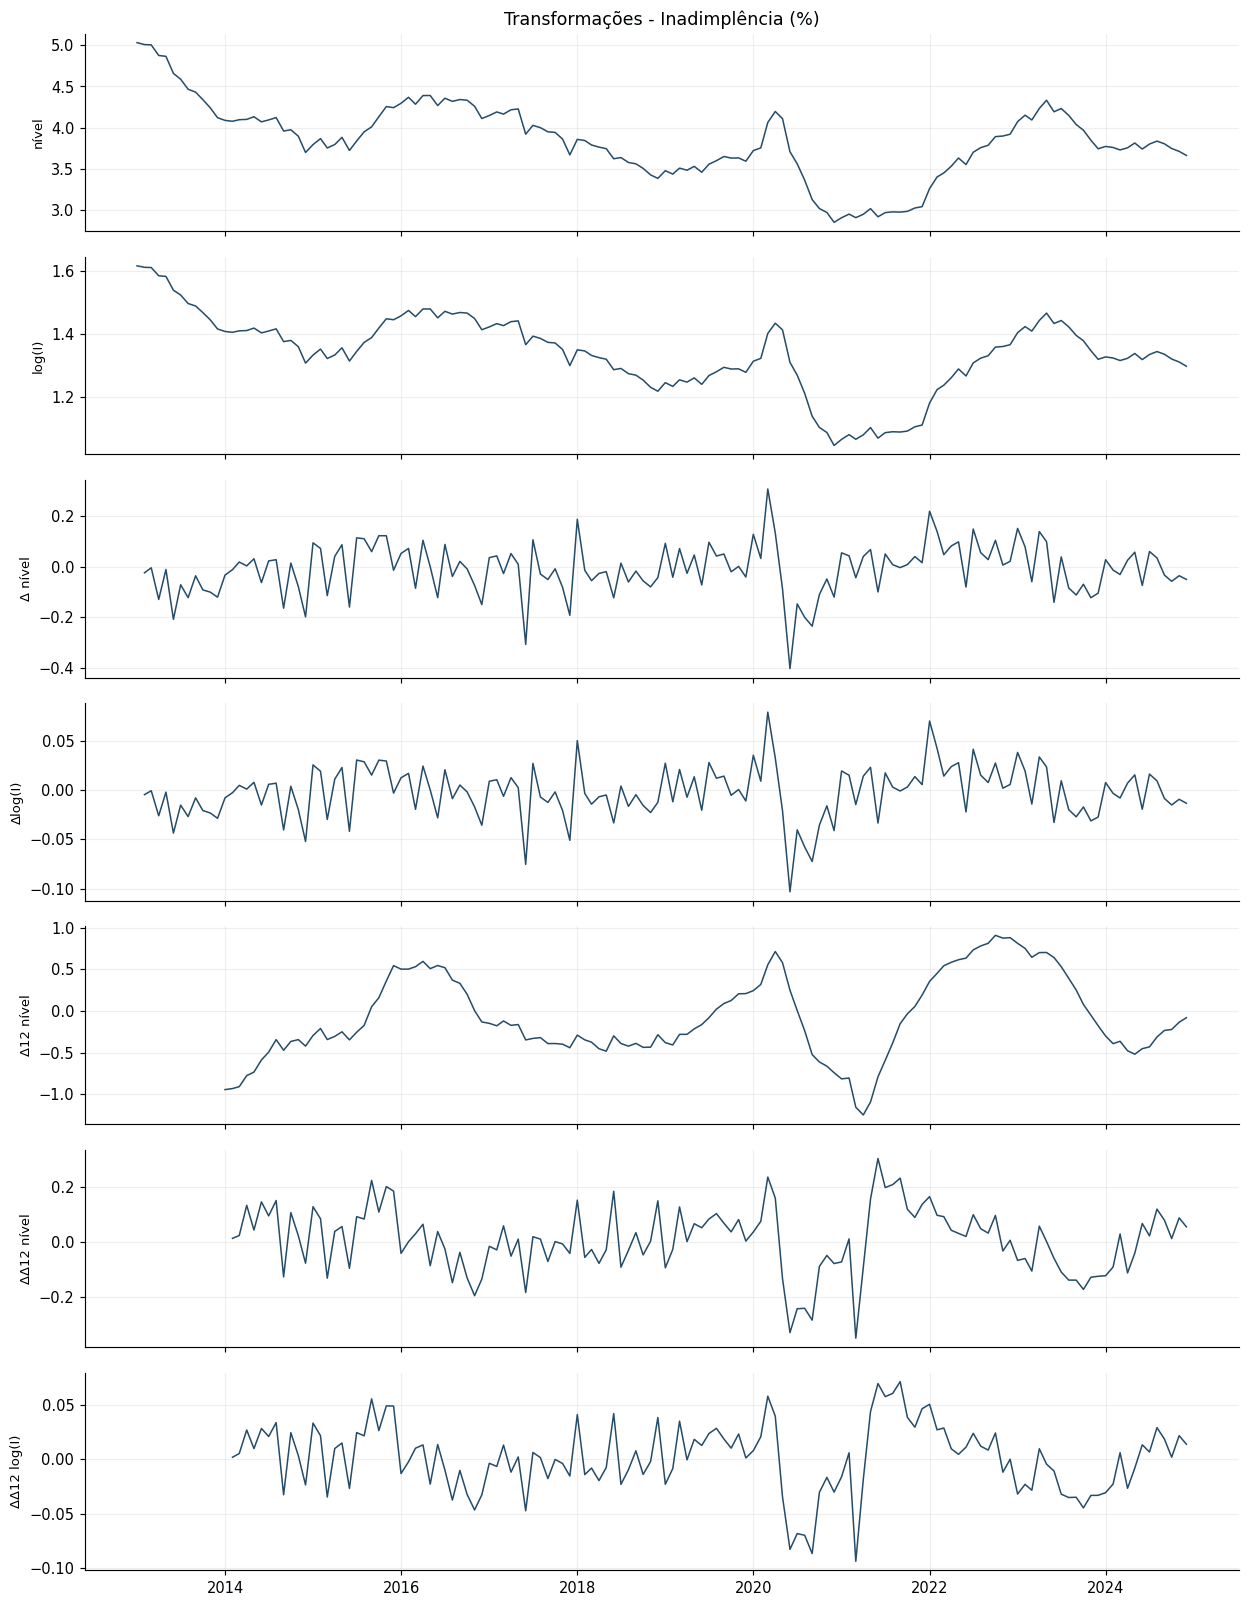

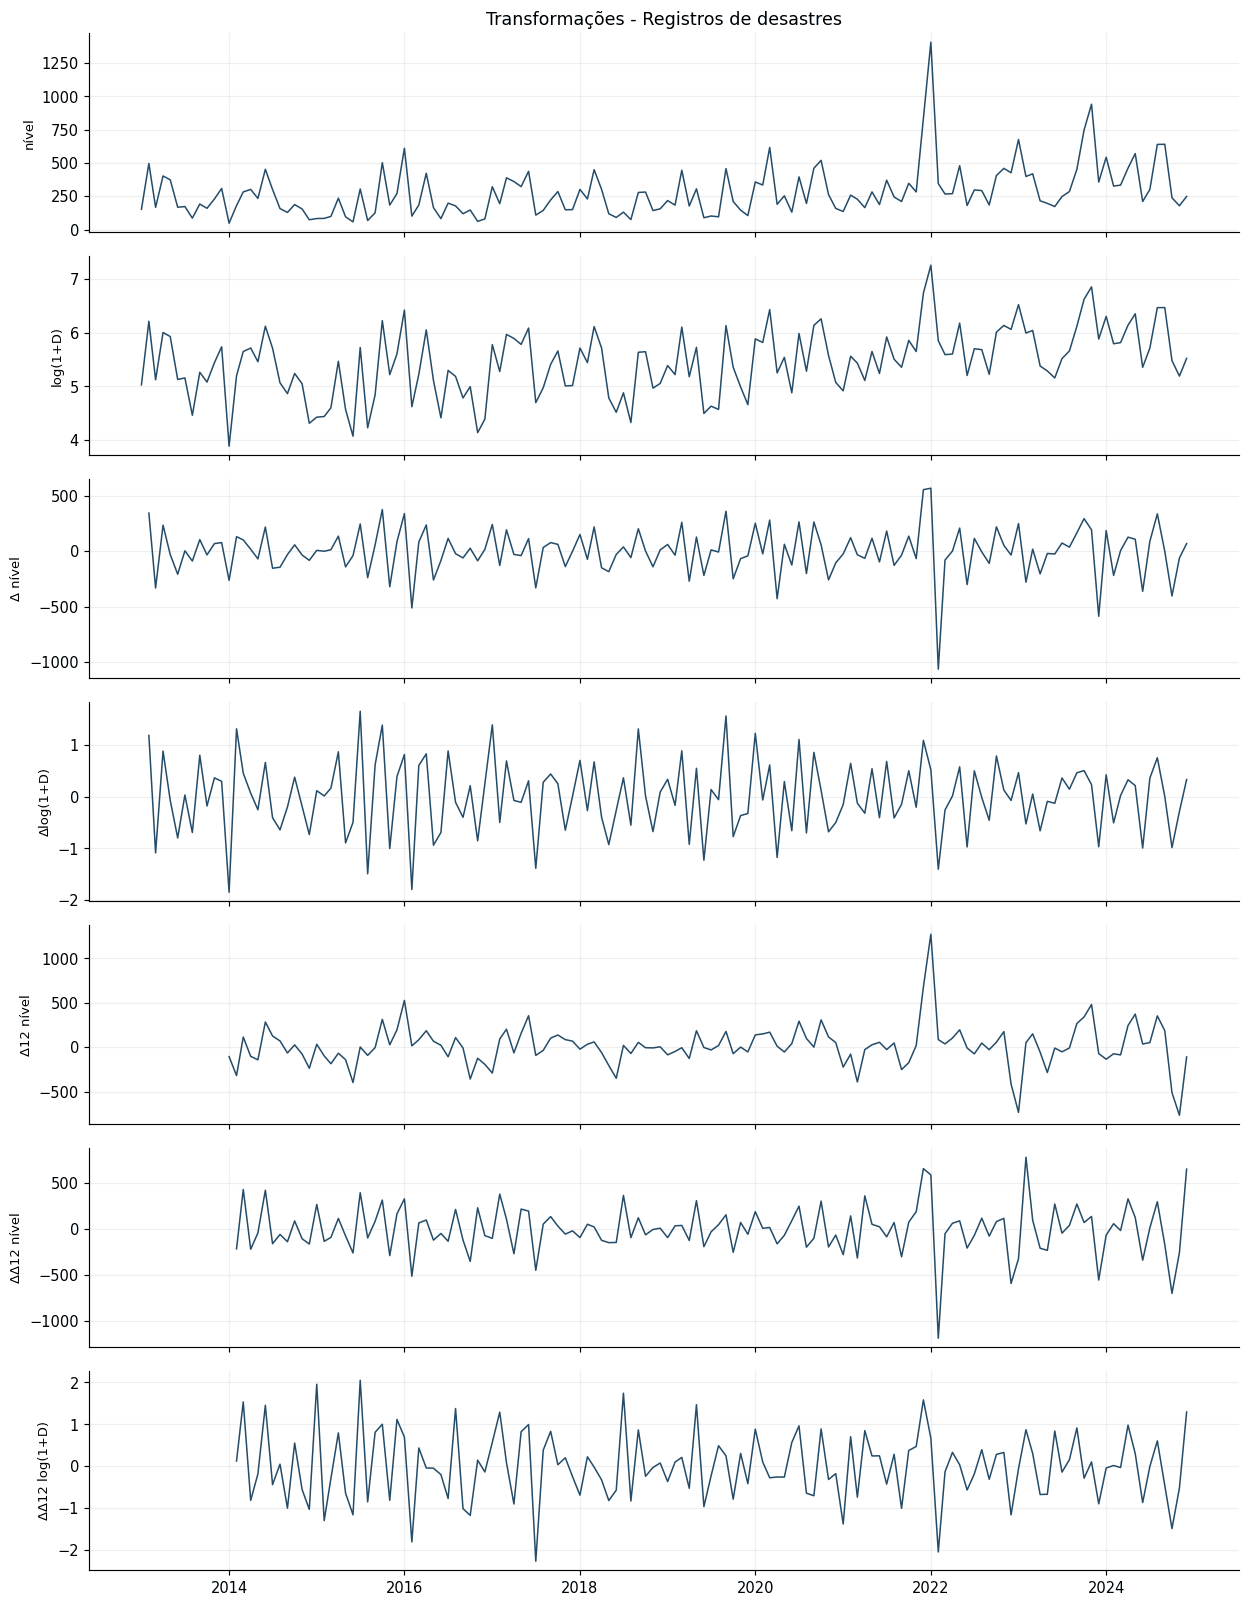

In [6]:
for nome, candidatos in transformadas.items():
    fig, axes = plt.subplots(len(candidatos), 1, figsize=(12, 2.2*len(candidatos)), sharex=True)
    for ax, (rotulo, s) in zip(axes, candidatos.items()):
        ax.plot(s.index, s, lw=1.05, color="#254c68")
        ax.set_ylabel(rotulo, fontsize=9)
    axes[0].set_title("Transformações - " + nome)
    fig.tight_layout()
    plt.show()

## 7. Decomposição das transformações selecionadas

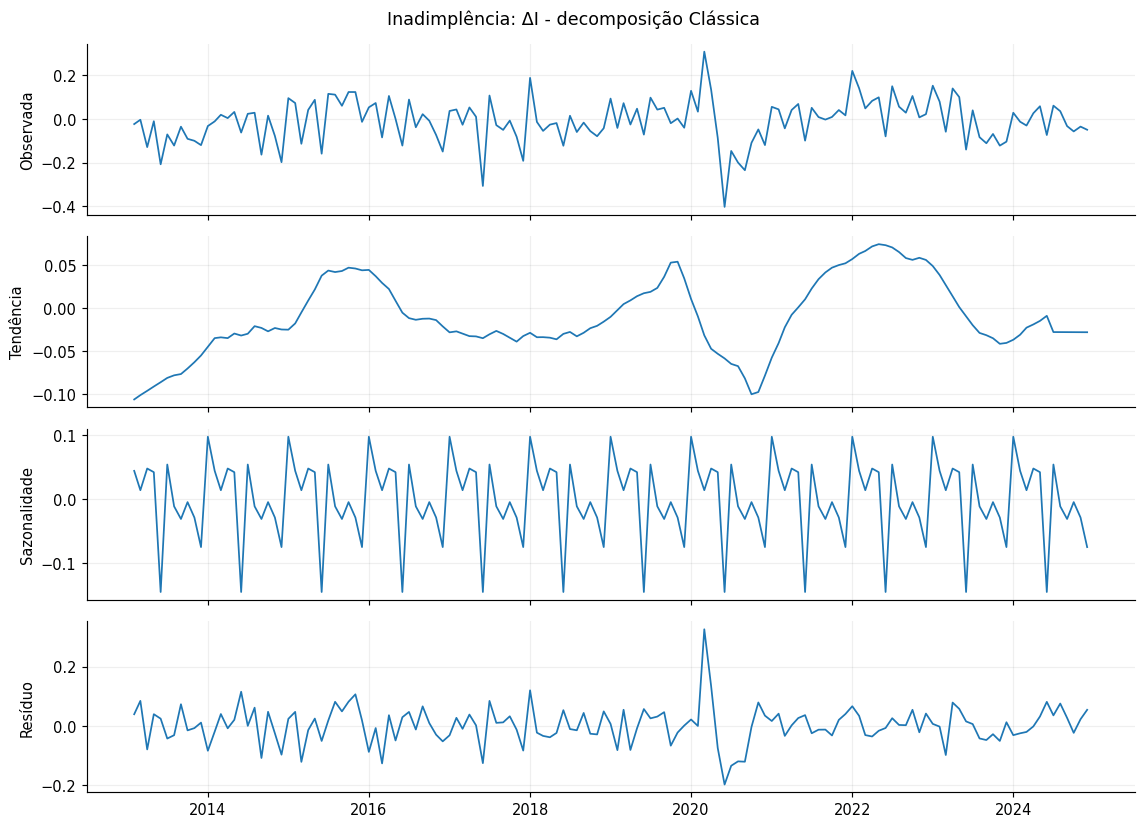

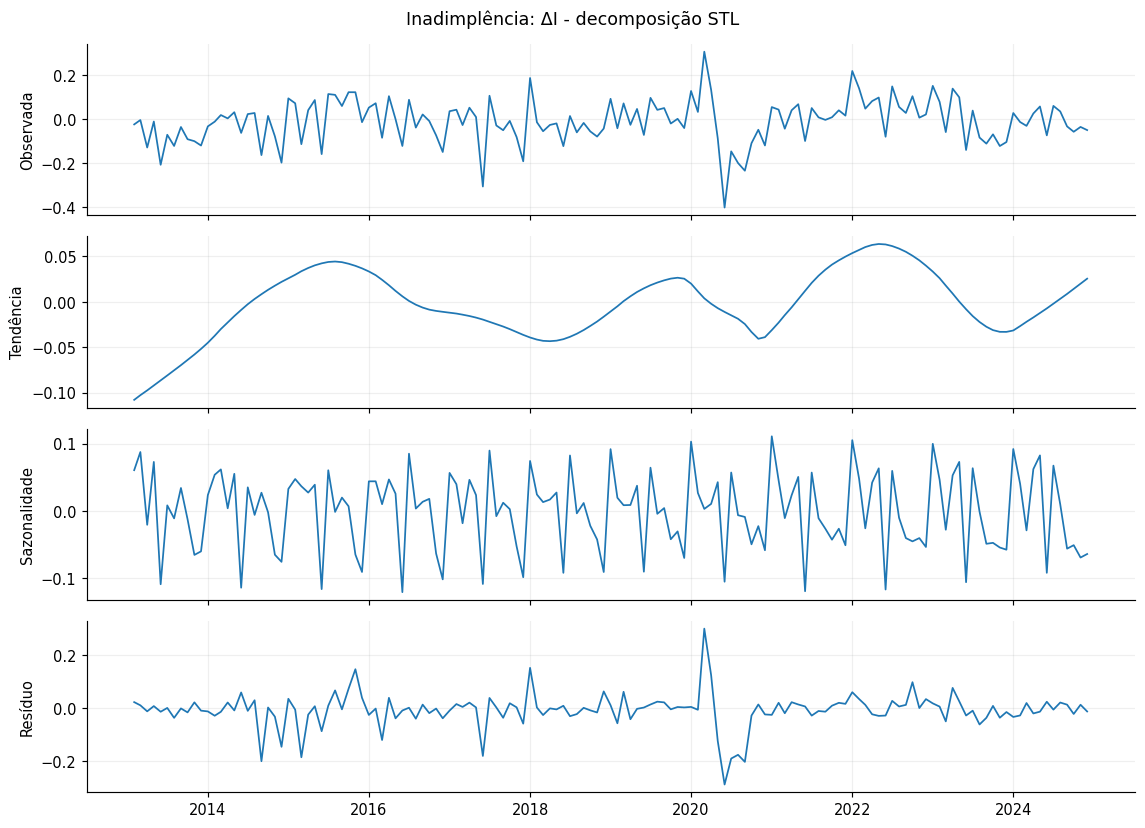

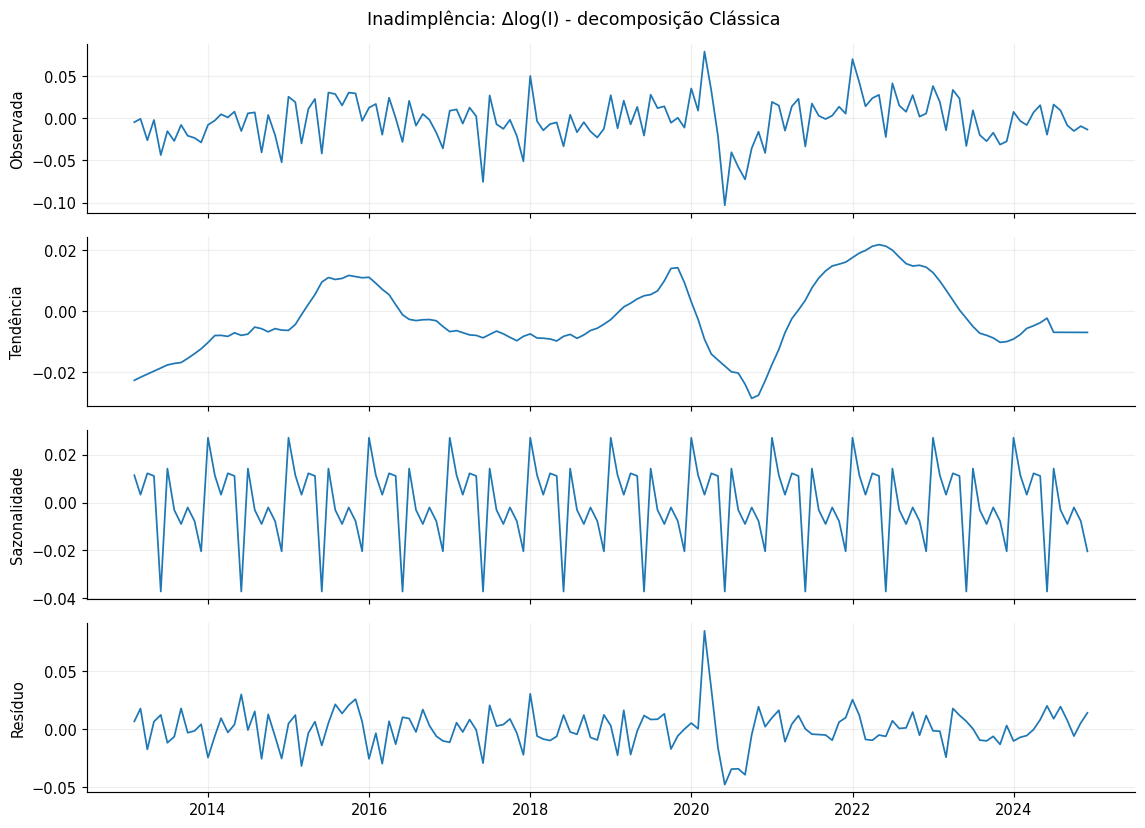

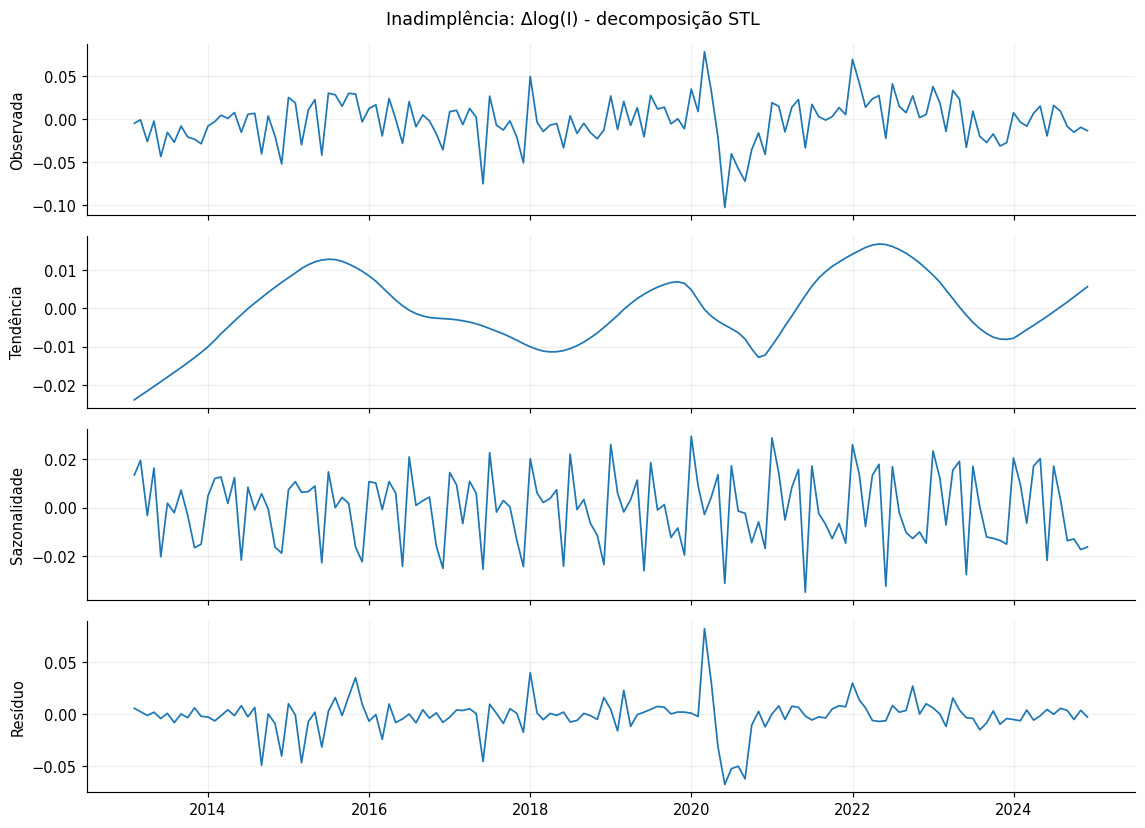

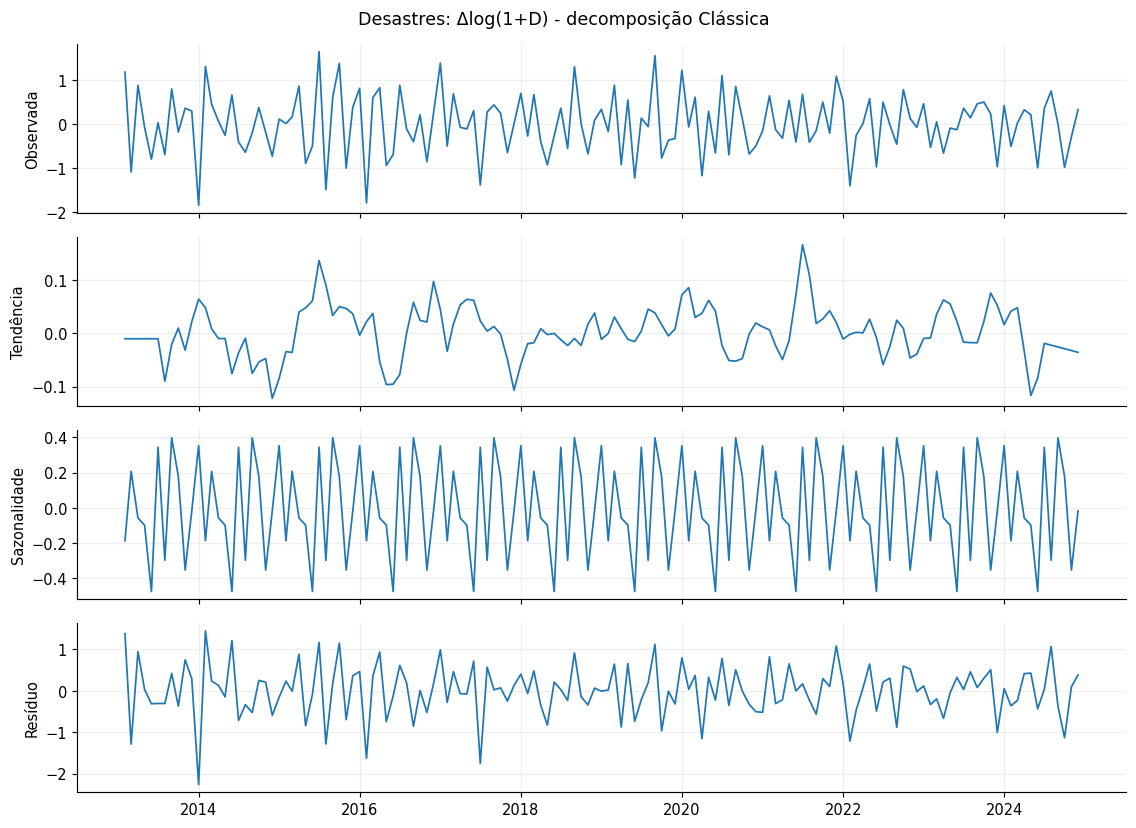

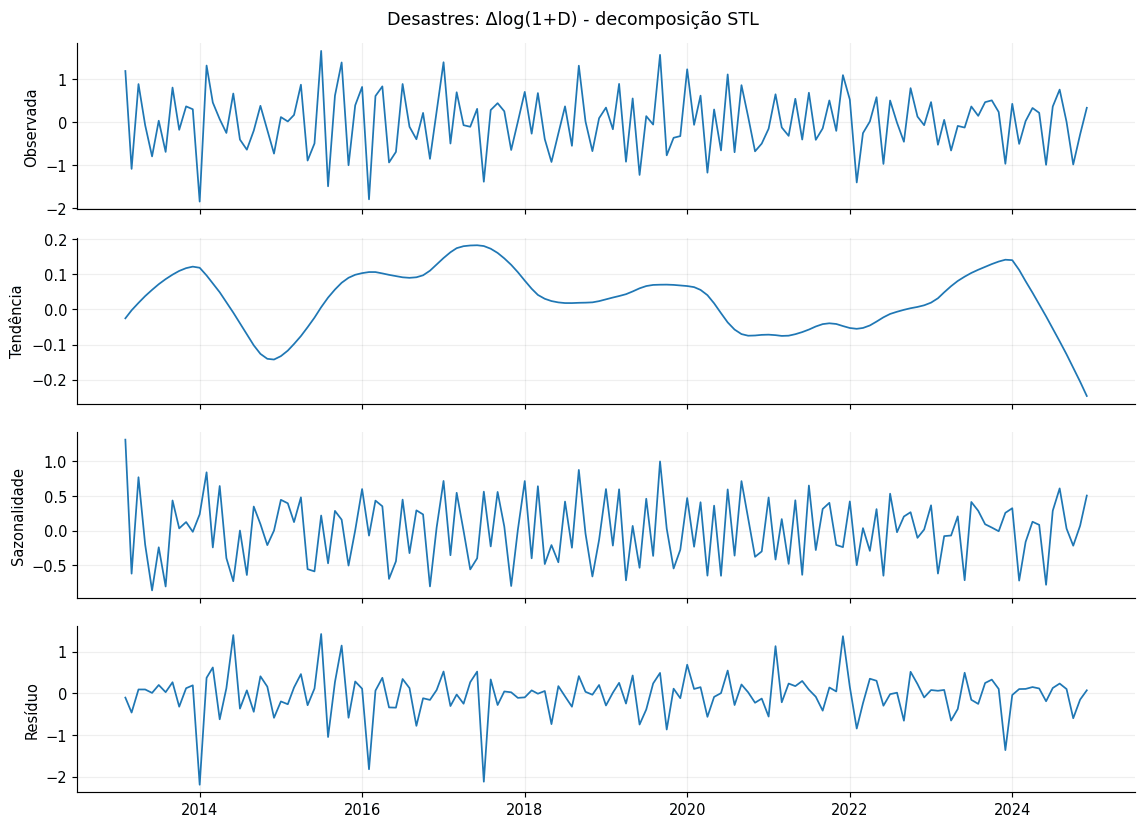

02_estacionariedade.ipynb::cell_9:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
02_estacionariedade.ipynb::cell_9:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
02_estacionariedade.ipynb::cell_9:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.


In [7]:
selecoes = {
    "Inadimplência: ΔI": transformadas["Inadimplência (%)"]["Δ nível"],
    "Inadimplência: Δlog(I)": transformadas["Inadimplência (%)"]["Δlog(I)"],
    "Desastres: Δlog(1+D)": transformadas["Registros de desastres"]["Δlog(1+D)"],
}
for rotulo, s in selecoes.items():
    mostrar_decomposicoes(s.dropna(), rotulo)

A decomposição das séries transformadas permite verificar o que permaneceu da sazonalidade e da tendência após a diferenciação. A transformação escolhida para a primeira abordagem nacional foi **ΔI**, mas as modelagens estaduais posteriores usam **Δlog(I)**; ambas são expostas aqui para não confundir os resultados das etapas.

## 8. Testes ADF e KPSS: hipóteses e critérios

- **ADF:** H0 de raiz unitária; p < 0,05 indica rejeição da raiz unitária no modelo de regressão determinística testado.
- **KPSS:** H0 de estacionariedade; p < 0,05 indica rejeição da estacionariedade no modelo testado.
- Serão testadas especificações com **constante (`c`)** e com **constante e tendência (`ct`)** para níveis e transformações. Os p-valores do KPSS podem estar limitados à tabela de referência.
- Resultado favorável: ADF rejeita H0 e KPSS não rejeita H0. Combinações divergentes são classificadas como inconclusivas. A estacionariedade não é comprovada apenas por não rejeitar KPSS.

In [8]:
def testar_serie(serie, nome, transformacao, recorte, deterministico):
    x = pd.Series(serie).replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    registro = {"recorte": recorte, "série": nome, "transformação": transformacao,
                "determinístico": deterministico, "n": len(x), "ADF p": np.nan,
                "KPSS p": np.nan, "lags ADF": np.nan, "lags KPSS": np.nan,
                "interpretação": "não estimável"}
    if len(x) < 24 or x.nunique() < 3:
        return registro
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", InterpolationWarning)
            adf = adfuller(x, regression=deterministico, autolag="AIC")
            kps = kpss(x, regression=deterministico, nlags="auto")
        registro.update({"ADF p": adf[1], "KPSS p": kps[1],
                         "lags ADF": adf[2], "lags KPSS": kps[2]})
        if adf[1] < .05 and kps[1] >= .05:
            registro["interpretação"] = "favorável à estacionariedade"
        elif adf[1] >= .05 and kps[1] < .05:
            registro["interpretação"] = "indício contrário à estacionariedade"
        else:
            registro["interpretação"] = "inconclusivo/divergente"
    except (ValueError, ZeroDivisionError, OverflowError) as exc:
        registro["interpretação"] = "não estimável: " + str(exc)[:48]
    return registro

testes = []
for recorte, parte in RECORTES.items():
    for nome, candidatos in transformadas.items():
        for transformacao, s in candidatos.items():
            for det in ["c", "ct"]:
                testes.append(testar_serie(s.loc[parte.index], nome, transformacao, recorte, det))
resultados = pd.DataFrame(testes)
print("Quantidade de testes ADF/KPSS por especificação:", len(resultados))
display(resultados.groupby(["recorte", "interpretação"]).size().rename("quantidade").to_frame())

Quantidade de testes ADF/KPSS por especificação: 56


quantidade
recorte      interpretação                                   
completo     favorável à estacionariedade                  16
             inconclusivo/divergente                        7
             indício contrário à estacionariedade           5
pré-pandemia favorável à estacionariedade                  12
             inconclusivo/divergente                        9
             indício contrário à estacionariedade           7

02_estacionariedade.ipynb::cell_20:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
02_estacionariedade.ipynb::cell_20:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
02_estacionariedade.ipynb::cell_20:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 o

## 9. ADF e KPSS apresentados por série e recorte

In [9]:
for recorte in RECORTES:
    for nome in transformadas:
        print("\n", recorte.upper(), "-", nome)
        tabela = resultados.loc[(resultados["recorte"] == recorte) &
                                (resultados["série"] == nome),
                                ["transformação", "determinístico", "n", "ADF p", "KPSS p",
                                 "lags ADF", "lags KPSS", "interpretação"]]
        display(tabela.round(5))


 PRÉ-PANDEMIA - Inadimplência (%)

 PRÉ-PANDEMIA - Registros de desastres

 COMPLETO - Inadimplência (%)

 COMPLETO - Registros de desastres


,transformação,determinístico,n,ADF p,KPSS p,lags ADF,lags KPSS,interpretação
0,nível,c,85,0.12326,0.01000,6,5,indício contrário à estacionariedade
1,nível,ct,85,0.06316,0.08191,6,5,inconclusivo/divergente
2,log(I),c,85,0.12208,0.01000,6,5,indício contrário à estacionariedade
3,log(I),ct,85,0.06824,0.07297,6,5,inconclusivo/divergente
4,Δ nível,c,84,0.29975,0.10000,5,0,inconclusivo/divergente
5,Δ nível,ct,84,0.61958,0.02486,5,1,indício contrário à estacionariedade
6,Δlog(I),c,84,0.34287,0.10000,5,1,inconclusivo/divergente
7,Δlog(I),ct,84,0.65133,0.03371,5,2,indício contrário à estacionariedade
8,Δ12 nível,c,73,0.14620,0.10000,3,5,inconclusivo/divergente
9,Δ12 nível,ct,73,0.39819,0.02186,3,5,indício contrário à estacionariedade


,transformação,determinístico,n,ADF p,KPSS p,lags ADF,lags KPSS,interpretação
14,nível,c,85,0.00150,0.10000,6,1,favorável à estacionariedade
15,nível,ct,85,0.00915,0.10000,6,1,favorável à estacionariedade
16,log(1+D),c,85,0.00000,0.10000,0,1,favorável à estacionariedade
17,log(1+D),ct,85,0.00000,0.10000,0,1,favorável à estacionariedade
18,Δ nível,c,84,0.00000,0.10000,4,20,favorável à estacionariedade
19,Δ nível,ct,84,0.00000,0.09886,4,19,favorável à estacionariedade
20,Δlog(1+D),c,84,0.00001,0.10000,10,25,favorável à estacionariedade
21,Δlog(1+D),ct,84,0.00014,0.05386,10,25,favorável à estacionariedade
22,Δ12 nível,c,73,0.00003,0.10000,11,3,favorável à estacionariedade
23,Δ12 nível,ct,73,0.00029,0.10000,11,3,favorável à estacionariedade


,transformação,determinístico,n,ADF p,KPSS p,lags ADF,lags KPSS,interpretação
28,nível,c,144,0.20263,0.01389,13,8,indício contrário à estacionariedade
29,nível,ct,144,0.35685,0.02166,13,8,indício contrário à estacionariedade
30,log(I),c,144,0.19576,0.01703,13,8,indício contrário à estacionariedade
31,log(I),ct,144,0.35289,0.02313,13,8,indício contrário à estacionariedade
32,Δ nível,c,143,0.01911,0.10000,12,6,favorável à estacionariedade
33,Δ nível,ct,143,0.08522,0.10000,12,6,inconclusivo/divergente
34,Δlog(I),c,143,0.02081,0.10000,12,7,favorável à estacionariedade
35,Δlog(I),ct,143,0.08854,0.10000,12,6,inconclusivo/divergente
36,Δ12 nível,c,132,0.06447,0.10000,13,6,inconclusivo/divergente
37,Δ12 nível,ct,132,0.18810,0.10000,13,6,inconclusivo/divergente


,transformação,determinístico,n,ADF p,KPSS p,lags ADF,lags KPSS,interpretação
42,nível,c,144,0.00000,0.01000,0,5,inconclusivo/divergente
43,nível,ct,144,0.00000,0.10000,0,3,favorável à estacionariedade
44,log(1+D),c,144,0.57143,0.01000,11,6,indício contrário à estacionariedade
45,log(1+D),ct,144,0.00009,0.09882,6,4,favorável à estacionariedade
46,Δ nível,c,143,0.00000,0.10000,12,26,favorável à estacionariedade
47,Δ nível,ct,143,0.00001,0.10000,12,26,favorável à estacionariedade
48,Δlog(1+D),c,143,0.00000,0.10000,10,14,favorável à estacionariedade
49,Δlog(1+D),ct,143,0.00000,0.10000,10,13,favorável à estacionariedade
50,Δ12 nível,c,132,0.00000,0.10000,11,2,favorável à estacionariedade
51,Δ12 nível,ct,132,0.00000,0.10000,11,2,favorável à estacionariedade


Os testes são apresentados um a um, sem trocar a hipótese nula de um teste pela do outro. Na avaliação original nacional completa, `ΔI` teve ADF p aproximadamente **0,0191** e KPSS p reportado como **0,10** na especificação com constante; `Δlog(1+D)` apresentou ADF muito baixo e KPSS de **0,10**. Esses resultados não garantem que todas as séries estaduais sejam estacionárias.

## 10. Gráficos ACF e PACF das séries originais e transformadas

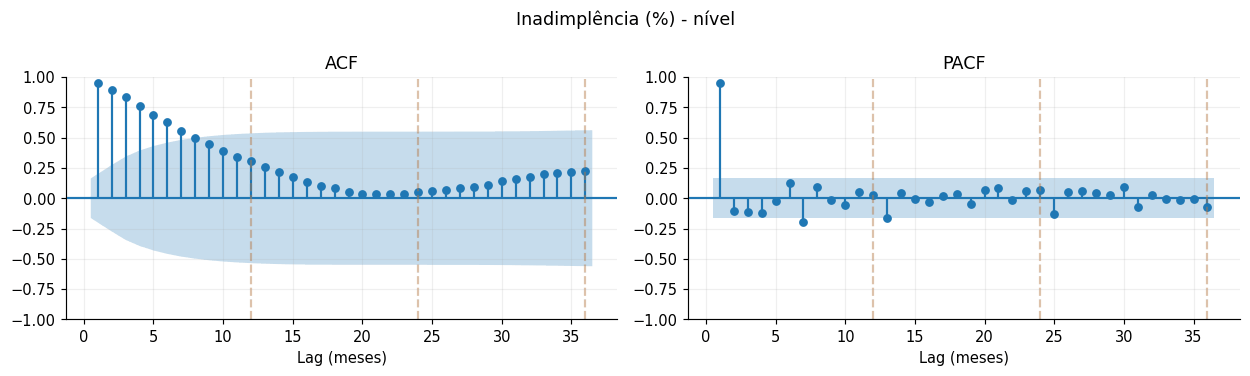

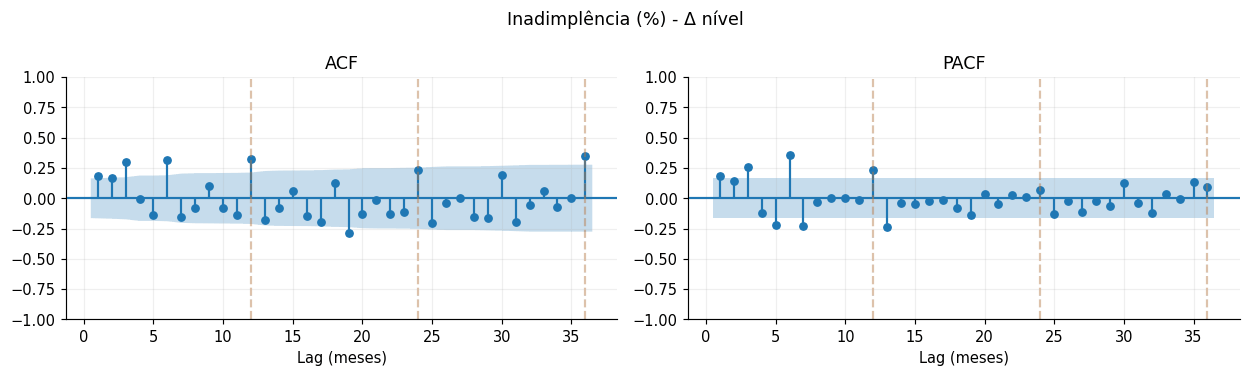

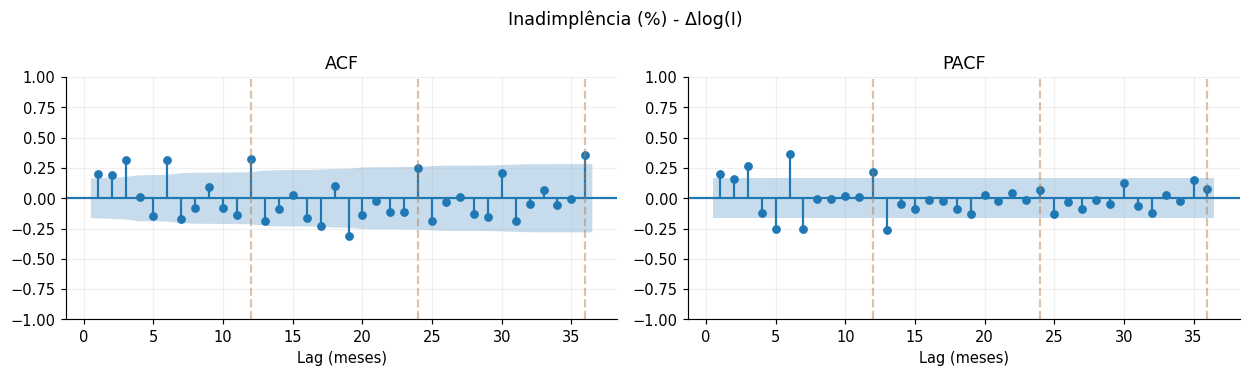

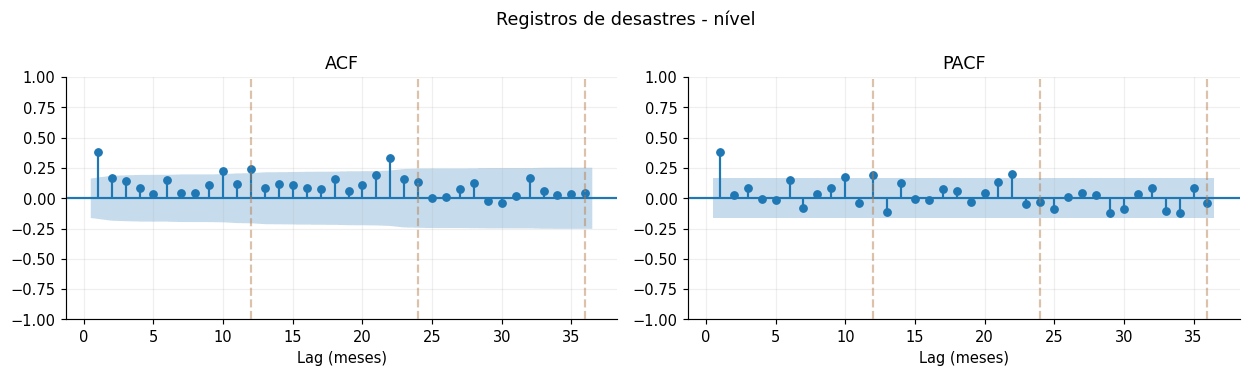

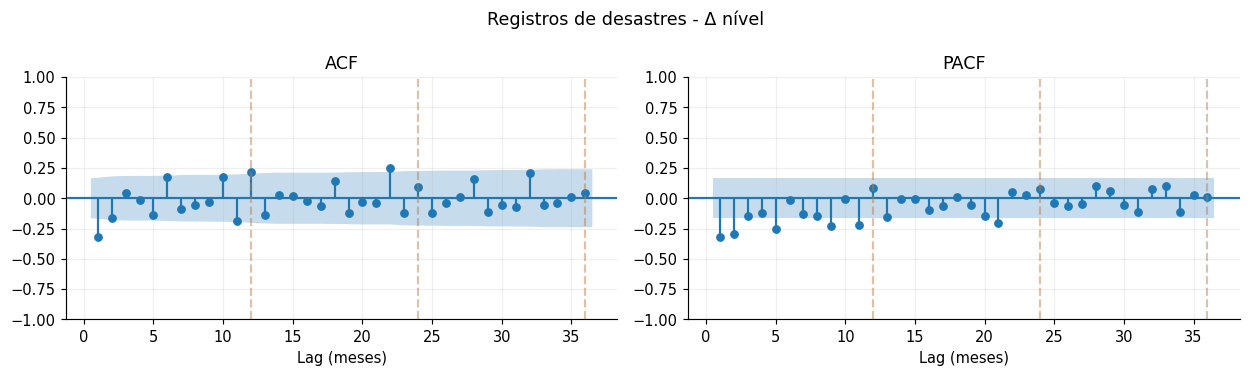

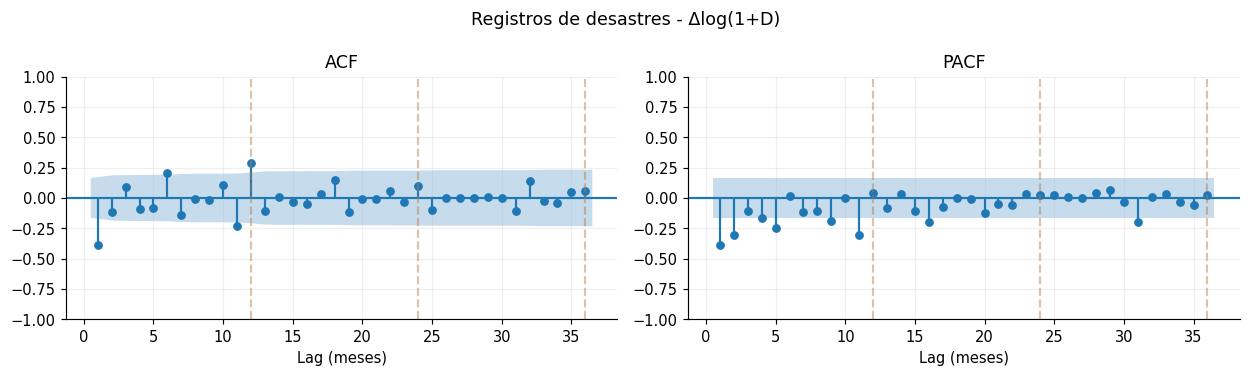

In [10]:
for nome, candidatos in transformadas.items():
    selecionadas = ["nível", "Δ nível", "Δlog(I)" if nome.startswith("Inadimplência") else "Δlog(1+D)"]
    for chave in selecionadas:
        s = candidatos[chave].dropna()
        nlags = min(36, len(s)//2-1)
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
        plot_acf(s, lags=nlags, ax=axes[0], zero=False, alpha=.05)
        plot_pacf(s, lags=nlags, ax=axes[1], zero=False, alpha=.05, method="ywm")
        axes[0].set_title("ACF")
        axes[1].set_title("PACF")
        for ax in axes:
            for lag in [12, 24, 36]:
                if lag <= nlags:
                    ax.axvline(lag, color="#b57845", ls="--", alpha=.45)
            ax.set_xlabel("Lag (meses)")
        fig.suptitle(nome + " - " + chave)
        fig.tight_layout()
        plt.show()

A ACF descreve a correlação com observações defasadas; a PACF descreve a associação com determinada defasagem após descontar lags intermediários. Os gráficos ajudam a investigar persistência e sazonalidade, mas não determinam isoladamente a ordem de modelos multivariados.

## 11. Diagnósticos estaduais usados nas modelagens seguintes

In [11]:
estadual = pd.read_csv(TAB / "revisao_estadual_20261019/estacionariedade_adf_kpss.csv")
print("Linhas de teste estadual:", len(estadual))
display(estadual.groupby(["periodo", "conclusao"]).size().rename("quantidade").to_frame().head(25))
display(estadual.loc[estadual["serie"].eq("y"),
                     ["uf", "periodo", "transformacao", "p_ADF", "p_KPSS", "conclusao"]].head(30))

Linhas de teste estadual: 918


quantidade
periodo conclusao                                             
Pré     favorável à estacionariedade (não é prova)         180
        inconclusivo ou divergente                          36
        não determinado                                    107
        não testável                                       135
        sinais contrários à estacionariedade                 1
Total   favorável à estacionariedade (não é prova)         220
        inconclusivo ou divergente                          58
        não determinado                                     88
        não testável                                        92
        sinais contrários à estacionariedade                 1

,uf,periodo,transformacao,p_ADF,p_KPSS,conclusao
0,AC,Pré,Delta log(I),3.677818e-18,0.100000,favorável à estacionariedade (não é prova)
17,AL,Pré,Delta log(I),1.221135e-16,0.100000,favorável à estacionariedade (não é prova)
34,AM,Pré,Delta log(I),6.489770e-18,0.100000,favorável à estacionariedade (não é prova)
51,AP,Pré,Delta log(I),4.343429e-22,0.100000,favorável à estacionariedade (não é prova)
68,BA,Pré,Delta log(I),2.760579e-01,0.100000,inconclusivo ou divergente
85,CE,Pré,Delta log(I),9.859018e-14,0.100000,favorável à estacionariedade (não é prova)
102,DF,Pré,Delta log(I),5.536370e-14,0.100000,favorável à estacionariedade (não é prova)
119,ES,Pré,Delta log(I),2.861496e-13,0.100000,favorável à estacionariedade (não é prova)
136,GO,Pré,Delta log(I),2.611888e-01,0.100000,inconclusivo ou divergente
153,MA,Pré,Delta log(I),4.428606e-01,0.100000,inconclusivo ou divergente


Os modelos estaduais de Granger e DLM utilizam `Δlog(I)` e `Δlog(1+D)` por UF, e os resultados de estacionariedade variam entre séries, recortes e tipologias. Como a base UF-mês não é distribuída no repositório, a tabela acima apresenta os testes estaduais já calculados e disponibilizados em CSV; os testes nacionais anteriores são reproduzidos diretamente neste caderno.

## 12. Conclusões para as etapas de modelagem

A inspeção temporal revelou diferenças de nível, variabilidade e sazonalidade entre inadimplência e desastres. A aplicação de transformações e a análise conjunta de ADF/KPSS ajudam a evitar relações espúrias. A série nacional exploratória adotou `ΔI` e `Δlog(1+D)`, enquanto os modelos estaduais usam `Δlog(I)` e `Δlog(1+D)`.

A análise de estacionariedade orienta a especificação, mas não substitui diagnósticos de resíduos nem assegura causalidade. O próximo notebook investiga precedência preditiva de Granger por estado e tipologia; os dois seguintes tratam de associações em painel e de comparação SARIMA/SARIMAX.